<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/EX14-supernova2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SUPERNOVA 2**


<>:8: SyntaxWarning: invalid escape sequence '\m'
<>:8: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_884/1232702517.py:8: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel("$\mu$")


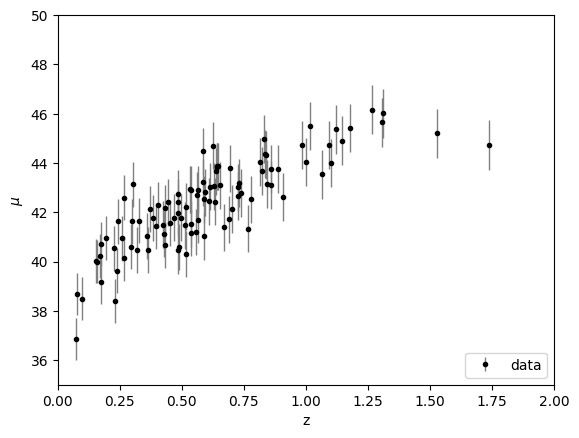

In [ ]:
from astroML.datasets import generate_mu_z
from matplotlib import pyplot as plt

z_sample, mu_sample, dmu = generate_mu_z(100, random_state=1234) # YOU CANNOT CHANGE THIS

plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1,label='data')
plt.xlabel("z")
plt.ylabel("$\mu$")
plt.legend(loc='lower right')
plt.xlim(0,2)
plt.ylim(35,50);

*  **Exploration of the GPR sklearn function**

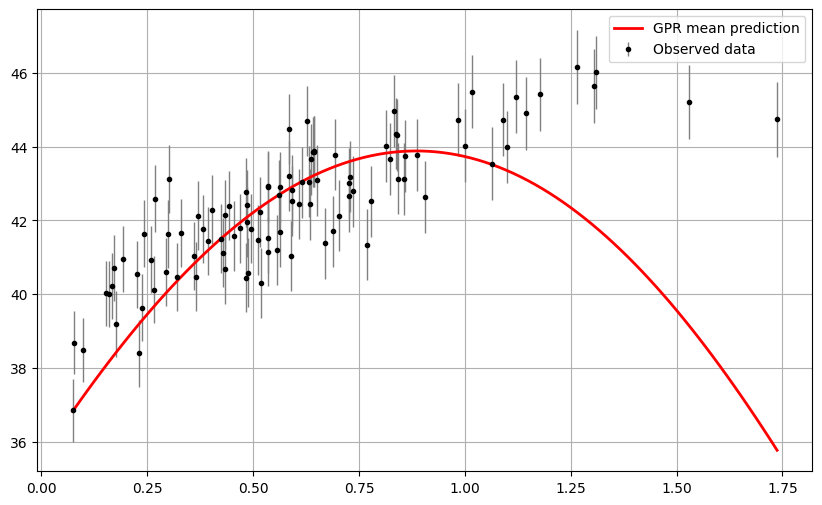

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel
import numpy as np

z= z_sample.reshape(-1,1)
z_grid=np.linspace(np.min(z_sample),np.max(z_sample),len(z_sample))

gpr= GaussianProcessRegressor(random_state=0,alpha=dmu**2) #alpha can be interpreted as variance
gpr.fit(z, mu_sample)
mu_pred, mu_err = gpr.predict(z_grid.reshape(-1,1),
                         return_std=True)

plt.figure(figsize=(10, 6))
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1, label='Observed data')
plt.plot(z_grid, mu_pred, 'r', lw=2, label='GPR mean prediction')
plt.grid()
plt.legend()



*  **CV BANDWIDTH ASSUMING KERNEL= RBF**




In [ ]:
#an array of dmu produces an error during CV inside the gpr,(dim: 100 vs 80) for this quick optimizzation i assumed dmu as homoschedastic (so i can treat alpha as a scalar)

dmu_mean=np.mean(dmu)
std_dmu = np.std(dmu)
print(std_dmu/dmu_mean)

0.033392715792981795


In [ ]:
from sklearn.model_selection import GridSearchCV

alpha=dmu_mean**2

bandwidth_range = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0]
param_grid = {
    'kernel': [
        RBF(length_scale=l, length_scale_bounds='fixed')
        for l in bandwidth_range
    ]
}


gpr = GaussianProcessRegressor(optimizer=None, random_state=0,alpha=alpha)
grid_search = GridSearchCV(
    estimator=gpr,
    param_grid=param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid_search.fit(z, mu_sample)

best_kernel = grid_search.best_params_['kernel']
best_bandwidth = best_kernel.length_scale


*  plotting with optimized bandwidth

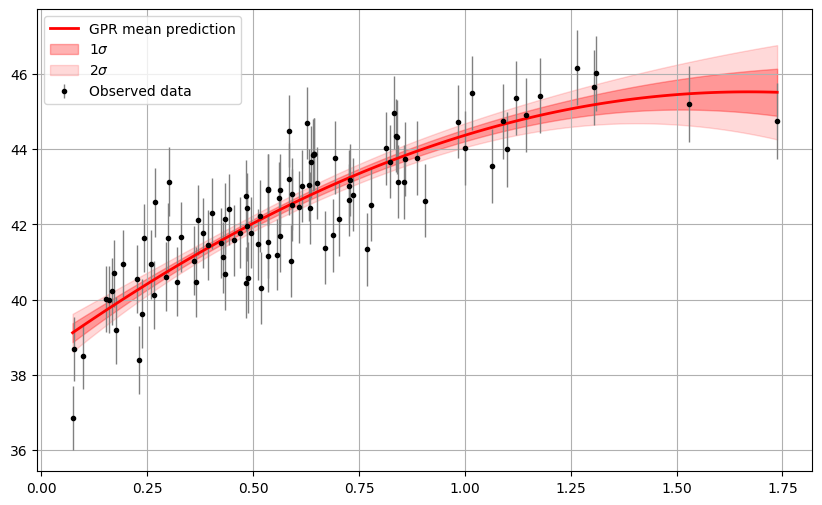

In [ ]:
gpr= GaussianProcessRegressor(random_state=42,alpha=dmu**2,kernel=ConstantKernel(0.5, (1e-3, 1e3))*RBF(length_scale=best_bandwidth)) #alpha can be interpreted as variance
gpr.fit(z, mu_sample)
mu_pred, mu_err = gpr.predict(z_grid.reshape(-1,1),
                         return_std=True)

plt.figure(figsize=(10, 6))
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1, label='Observed data')
plt.plot(z_grid, mu_pred, 'r', lw=2, label='GPR mean prediction')

#1σ and 2σ confidence intervals
plt.fill_between(z_grid, mu_pred - mu_err, mu_pred + mu_err, color='red', alpha=0.3, label=r'1$\sigma$')
plt.fill_between(z_grid, mu_pred - 2*mu_err, mu_pred + 2*mu_err, color='red', alpha=0.15, label=r'2$\sigma$')
plt.grid()
plt.legend()


*  **predicting data**




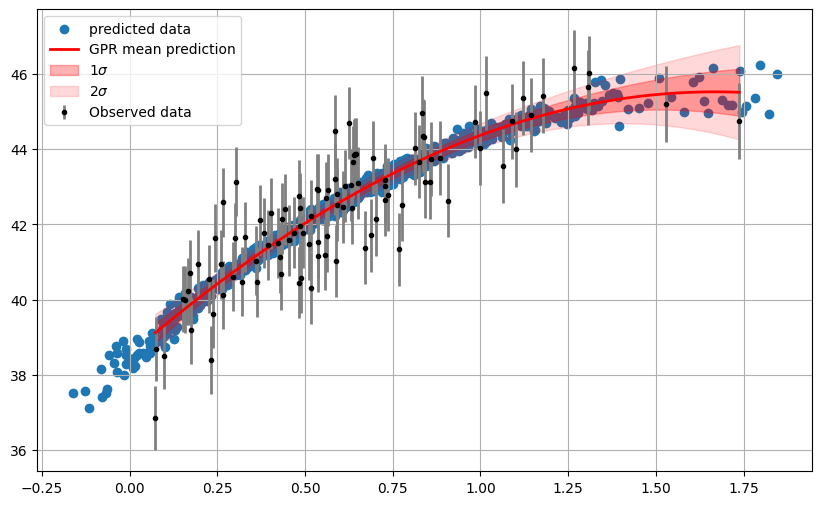

In [ ]:
from scipy.stats import gaussian_kde

# kde pdf extimation
z_pdf = gaussian_kde(z_sample)
z_fake = z_pdf.resample(10 * len(z_sample)).reshape(-1,1)
z_grid2=np.linspace(np.min(z_fake),np.max(z_fake),len(z_fake))

mu_fake_mean,mu_fake_std=gpr.predict(z_fake.reshape(-1,1),return_std=True)
mu_fake=np.random.normal(mu_fake_mean,mu_fake_std)

plt.figure(figsize=(10, 6))
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=2, label='Observed data')
plt.scatter(z_fake, mu_fake, label='predicted data')
plt.plot(z_grid, mu_pred, 'r', lw=2, label='GPR mean prediction')

#1σ and 2σ confidence intervals
plt.fill_between(z_grid, mu_pred - mu_err, mu_pred + mu_err, color='red', alpha=0.3, label=r'1$\sigma$')
plt.fill_between(z_grid, mu_pred - 2*mu_err, mu_pred + 2*mu_err, color='red', alpha=0.15, label=r'2$\sigma$')
plt.grid()
plt.legend()






### Part 3 (for the exam)

*(I know this assignment is longer and more convoluted, but we're getting towards the end of the class and it's important to draw connections between the different things we've done)*

We now have a suite of **data-driven** predictive models for our supernova dataset (from polynomials to GPR). That is: we can faithfully predict how a future redshift/distance measurement will look like given the current sample.

This is already great and these kind of tools are immensely useful in a variety of contexts (also involving a lot of money: suppose you want to predict how much a give financial asset will perform on tomorrow's stock market... You  might not really care about expressing the underlying financial model in simple terms, as long as your investments are profitable).

For the case of supernovae, however, we have do have physical theory which is $\Lambda$CDM. We can do a **parametric** fit (and hopehully by now the difference between "parametric" and "data driven" fit is clear in your head)

- First, refresh your cosmology and write down the predicted relationship between the distance module $\mu$ and the redshift $\sigma$. *Hint* I always forget these things, my to-go reference is [Hogg (2010)](https://arxiv.org/abs/astro-ph/9905116). The answer is:

$$\mu = 5 \log \left( \frac{c/H_0} {10 {\rm pc}}(1+z)\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z^3)+\Omega_\Lambda}} \right) $$

- Assuming a flat Universe,  we have a parametric non-linear model for $\mu(z)$ that depends on two parameters, the Hubble constant $H_0$ and the matter content of the Universe $\Omega_m$
- It's a very non-linear model. Fit it to the data, however you want to do it, using tecniques we've seen throughout the course. Some ideas:
    - Set up a Bayesian framework and use MCMC.
    - Set up a fully-connected neural network (see end of the class).

- What are the measured value of $H_0$ and $\Omega_m$. What's they errors? Are they correlated?
- How would a model without dark energy (i.e. $\Omega_m=1$) perform? Do these data contain evidence of dark energy? (Hint: this is a model selection problem!)



## **BAYESIAN APPROACH**




In [ ]:
import dynesty
import matplotlib.pyplot as plt

In [ ]:
from astropy.cosmology import LambdaCDM
def model(z, theta):
    Om,H0=theta
    cosmo_tmp = LambdaCDM(H0=H0, Om0=Om, Ode0=1-Om)
    return cosmo_tmp.distmod(z).value

def logL(theta,y,x,sigma): #this parameter disposition is the one imposed by dynasty
#loglikelihood #need carefull normalizzation #heteroschedastic logl
  return -0.5*np.sum((((y-model(x,theta))**2)/(sigma**2))+np.log(2*np.pi*sigma**2))

# Define our uniform prior.
def ptform(u):
    #u unifor between 0 and 1 we need to morph it in what we need
    u1,u2 = u
    p1 = u1   #Om
    p2 = 200.0 * (u2)   #H0
    theta_prior = np.array([p1, p2])
    return theta_prior




In [ ]:
# "Static" nested sampling.
labels = ['Om','H0']
ndim = 2
sampler = dynesty.NestedSampler(logL, ptform, ndim,logl_args=[mu_sample,z_sample, dmu])
sampler.run_nested()
sresults = sampler.results

100%|█████████▉| 2218/2219 [05:52<00:00,  6.30it/s, +500 | bound: 3 | nc: 1 | ncall: 19539 | eff(%): 14.276 | loglstar: -132.813 | logz: -136.392 +/-  0.067 | dlogz:  0.001 >  0.509]


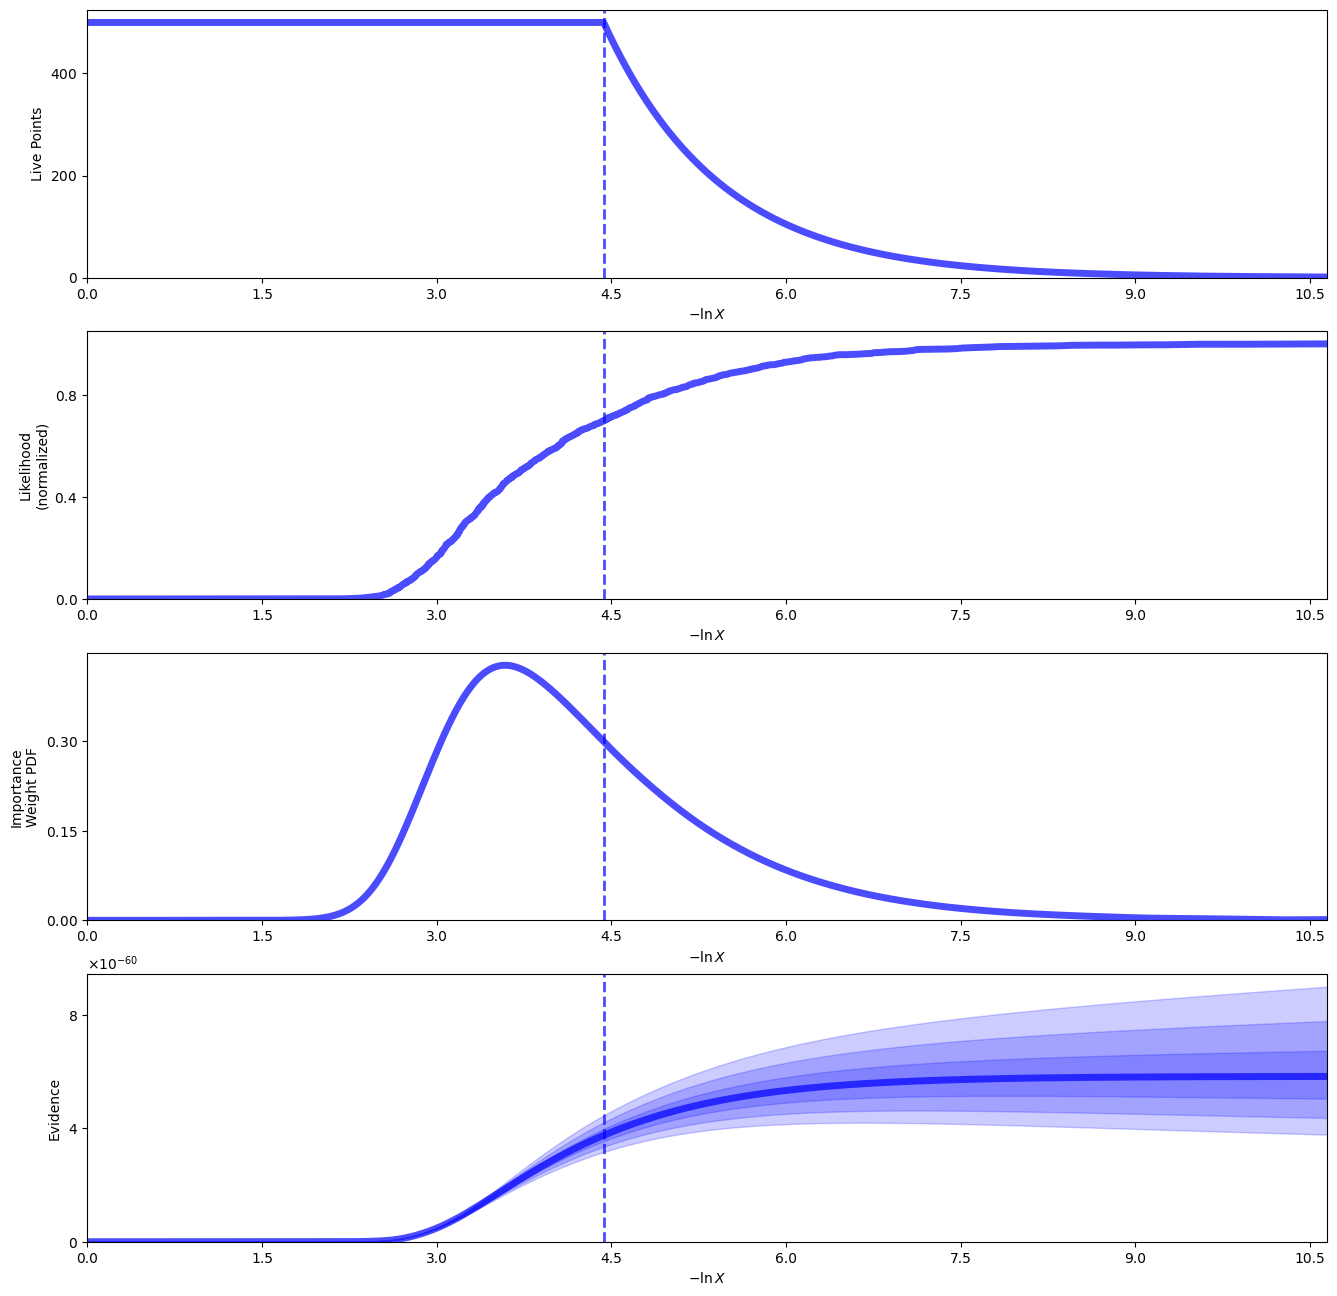

In [ ]:
from dynesty import plotting as dyplot

# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults)

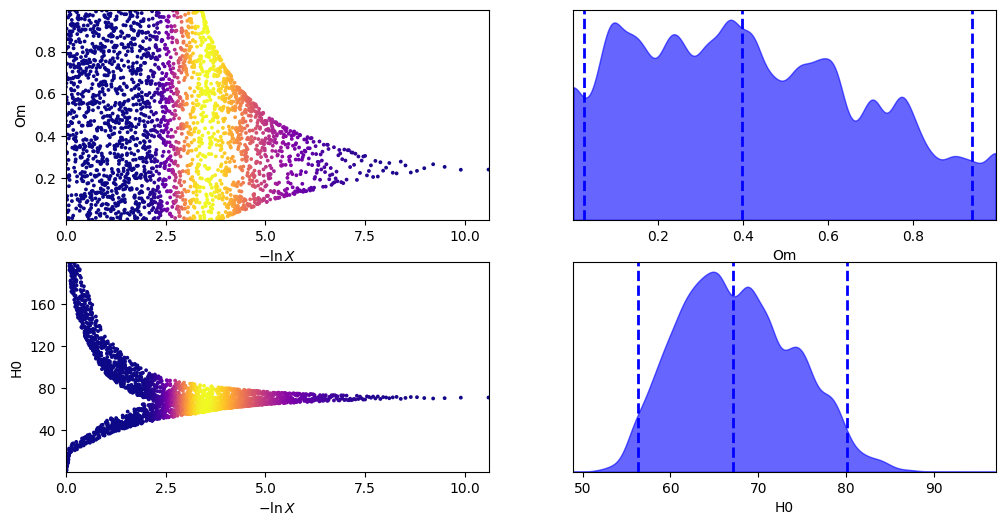

In [ ]:
tfig, taxes = dyplot.traceplot(sresults,labels=labels)

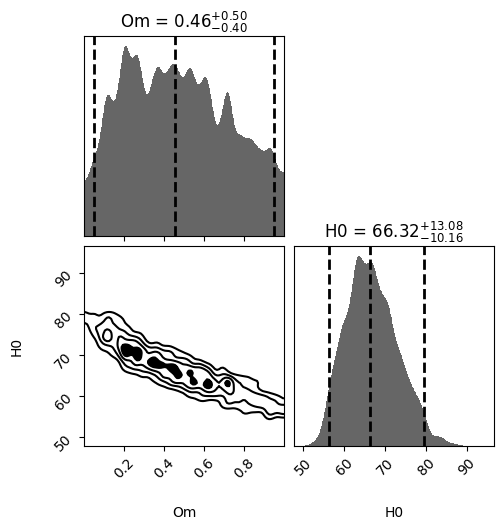

In [ ]:
cfig, caxes = dyplot.cornerplot(sresults,labels=labels, show_titles=True)

In [ ]:
from dynesty import utils as dyfunc


# Extract sampling results.
samples = sresults.samples  # samples
weights = np.exp(sresults.logwt - sresults.logz[-1])  # normalized weights

print('---------PARAMETERS------------')
# Compute credible region 90%.
for samps,label in zip(samples.T,labels):
  quantiles = [dyfunc.quantile(samps, [0.50,0.05, 0.95], weights=weights)]
  print(label + '\n: MEDIAN ' + str(quantiles[0][0]))
  print( '90% CREDIBLE REGION:' + str(quantiles[0][1])+'-'+str(quantiles[0][2]))


# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)



---------PARAMETERS------------
Om
: MEDIAN 0.39788715898142135
90% CREDIBLE REGION:0.05825008533868659-0.8865705751137699
H0
: MEDIAN 67.1177747359428
90% CREDIBLE REGION:57.687429455599656-78.67074643383688


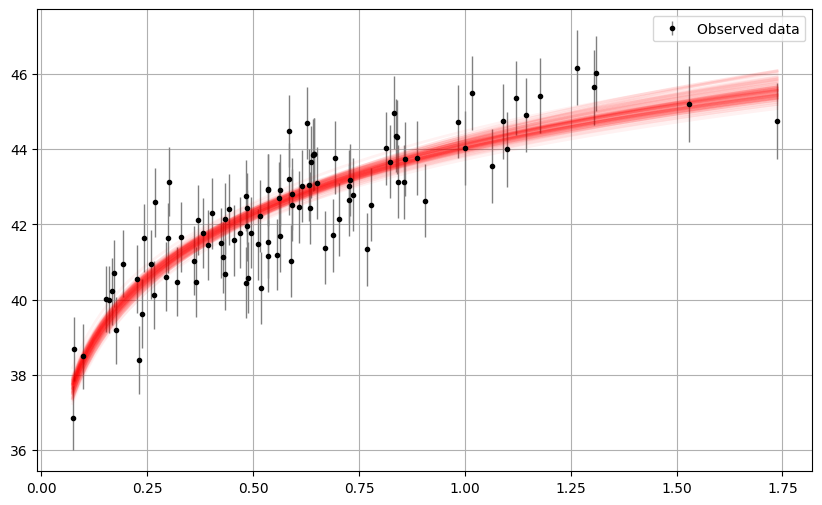

In [ ]:
plt.figure(figsize=(10, 6))
plt.errorbar(z_sample, mu_sample, dmu, fmt='.k', ecolor='gray', lw=1, label='Observed data')

#extrating 100 point for plot
samples_equal = dyfunc.resample_equal(samples, weights)
par = samples_equal[np.random.choice(len(samples_equal), size=100, replace=False)]
for med in par:
  plt.plot(z_grid, model(z_grid,med), 'r', lw=2,alpha=0.05) #label='GPR mean prediction')

plt.grid()
plt.legend()

Didn't liked the Om credibility region, probably caused by low number of sampling, but let's try to remove outliers in order to see if it improves

In [ ]:
z_in= z_sample[z_sample<1.5]
mu_in=mu_sample[z_sample<1.5]
dmu_in=dmu[z_sample<1.5]

# "Static" nested sampling.
labels = ['Om','H0']
ndim = 2
sampler = dynesty.NestedSampler(logL, ptform, ndim,logl_args=[mu_in,z_in, dmu_in])
sampler.run_nested()
sresults = sampler.results


100%|█████████▉| 2188/2189 [05:40<00:00,  6.43it/s, +500 | bound: 2 | nc: 1 | ncall: 18859 | eff(%): 14.641 | loglstar: -130.602 | logz: -134.120 +/-  0.066 | dlogz:  0.001 >  0.509]


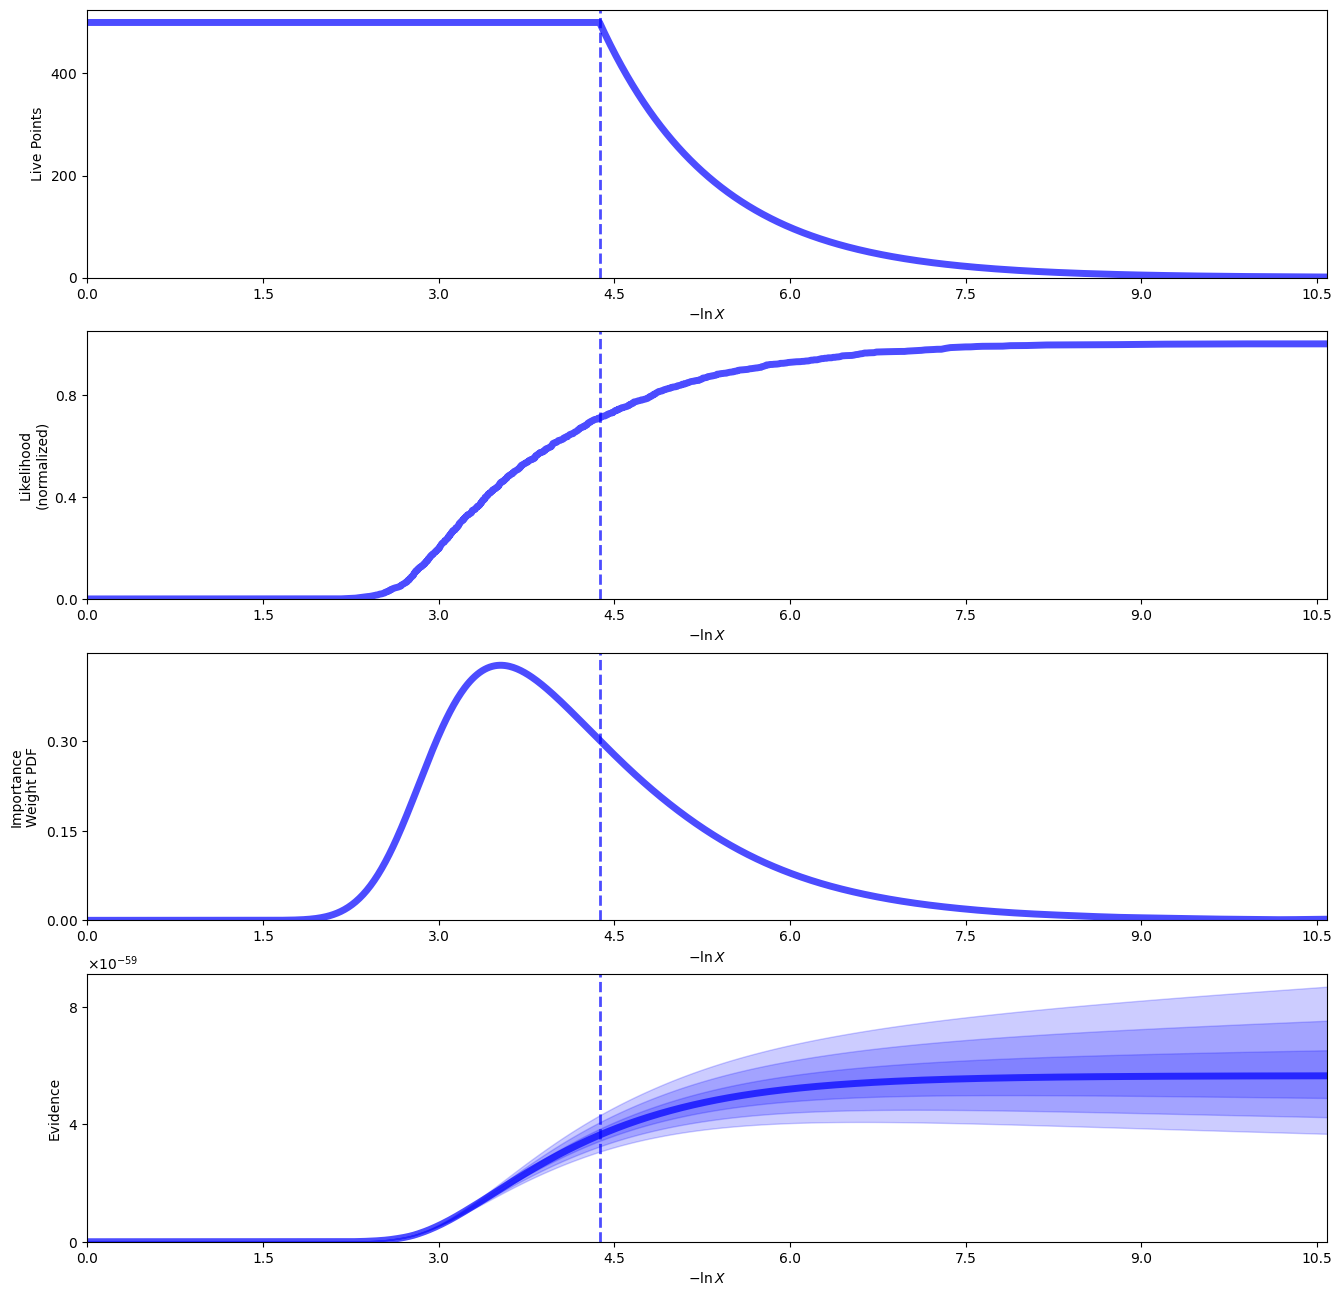

In [ ]:
# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults)

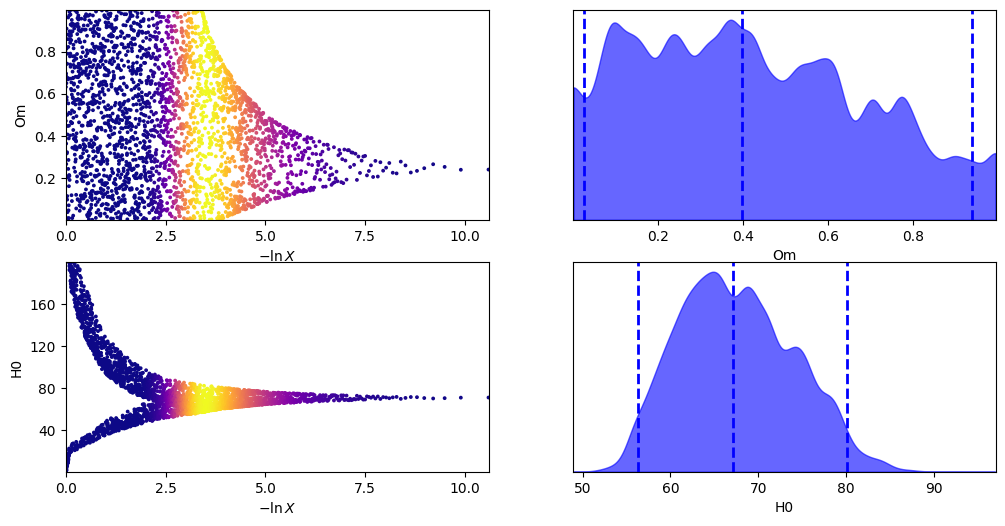

In [ ]:
tfig, taxes = dyplot.traceplot(sresults,labels=labels)

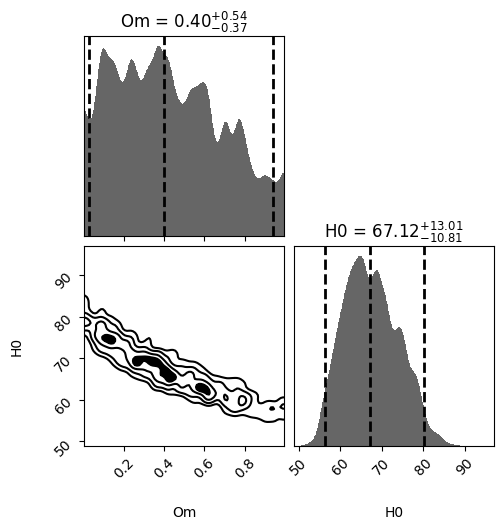

In [ ]:
cfig, caxes = dyplot.cornerplot(sresults,labels=labels, show_titles=True)

In [ ]:
# Extract sampling results.
samples = sresults.samples  # samples
weights = np.exp(sresults.logwt - sresults.logz[-1])  # normalized weights

print('---------PARAMETERS------------')
# Compute credible region 90%.
for samps,label in zip(samples.T,labels):
  quantiles = [dyfunc.quantile(samps, [0.50,0.05, 0.95], weights=weights)]
  print(label + '\n: MEDIAN ' + str(quantiles[0][0]))
  print( '90% CREDIBLE REGION:' + str(quantiles[0][1])+'-'+str(quantiles[0][2]))

# Compute weighted mean and covariance.
mean, cov = dyfunc.mean_and_cov(samples, weights)
print('Mean and covariance of parameters are: ' + str(mean) + '\n' + str(cov))

# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)

---------PARAMETERS------------
Om
: MEDIAN 0.39788715898142135
90% CREDIBLE REGION:0.05825008533868659-0.8865705751137699
H0
: MEDIAN 67.1177747359428
90% CREDIBLE REGION:57.687429455599656-78.67074643383688
Mean and covariance of parameters are: [ 0.42387655 67.53017671]
[[ 0.06625608 -1.46503468]
 [-1.46503468 42.01660879]]


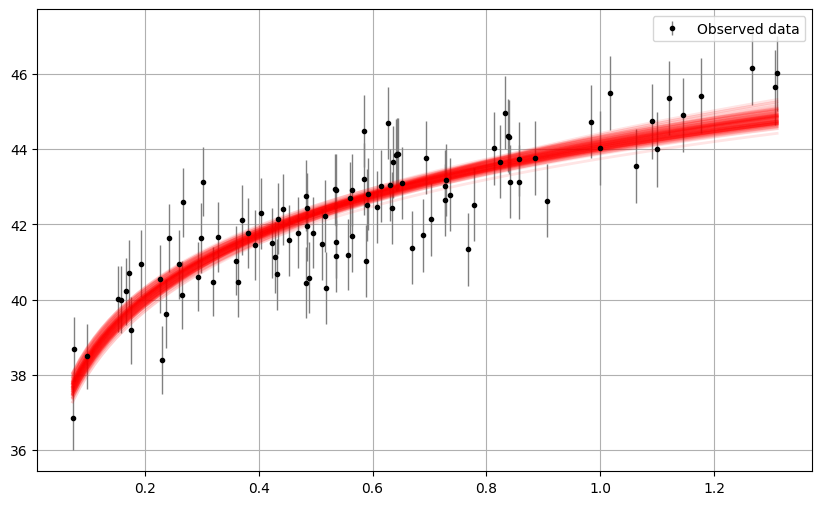

In [ ]:
z_grid=np.linspace(np.min(z_in),np.max(z_in),len(z_in))
plt.figure(figsize=(10, 6))
plt.errorbar(z_in, mu_in, dmu_in, fmt='.k', ecolor='gray', lw=1, label='Observed data')

#extrating 100 point for plot
samples_equal = dyfunc.resample_equal(samples, weights)
par = samples_equal[np.random.choice(len(samples_equal), size=100, replace=False)]
for med in par:
  plt.plot(z_grid, model(z_grid,med), 'r', lw=2,alpha=0.1) #label='GPR mean prediction')

plt.grid()
plt.legend()

* **MODEL SELECTION**


In [ ]:
def model_0(z, H0):
    Om=1
    cosmo_tmp = LambdaCDM(H0=H0, Om0=Om, Ode0=1-Om)
    return cosmo_tmp.distmod(z).value

def logL_0(H0,y,x,sigma): #this parameter disposition is the one imposed by dynasty
#loglikelihood #need carefull normalizzation #heteroschedastic logl
  return -0.5*np.sum((((y-model(x,H0))**2)/(sigma**2))+np.log(2*np.pi*sigma**2))

# Define our uniform prior.
def ptform_0(u):
    #u unifor between 0 and 1 we need to morph it in what we need
    p2 = 200.0 * (u)   #H0
    theta_prior = np.array([p2])
    return theta_prior

In [ ]:
# 1. Modello cosmologico con H0 convertito a scalare
def model_0(z, H0):
    # Se H0 è un array NumPy (es. da dynesty), estraiamo il valore scalare
    H0_scalar = float(np.squeeze(H0))
    Om = 1.0
    cosmo_tmp = LambdaCDM(H0=H0_scalar, Om0=Om, Ode0=1.0 - Om)
    return cosmo_tmp.distmod(z).value

# 2. Log-likelihood corretta
def logL_0(theta, y, x, sigma):
    # theta è fornito da dynesty come array 1D [H0]
    H0 = theta[0]
    mu_model = model_0(x, H0)

    # Calcolo della log-likelihood eteroschedastica
    res = y - mu_model
    return -0.5 * np.sum((res**2) / (sigma**2) + np.log(2 * np.pi * sigma**2))

# 3. Prior Transform uniforme per H0 tra 0 e 200
def ptform_0(u):
    # u è un array 1D uniformemente distribuito in [0, 1]
    H0_prior = 200.0 * u[0]
    return np.array([H0_prior])

# 4. Inizializzazione ed esecuzione del sampler dynesty
labels = ['H0']
ndim = 1

sampler_0 = dynesty.NestedSampler(
    logL_0,
    ptform_0,
    ndim,
    logl_args=[mu_in, z_in, dmu_in]
)
sampler_0.run_nested()
sresults_0 = sampler_0.results

100%|█████████▉| 2135/2136 [05:30<00:00,  6.46it/s, +500 | bound: 2 | nc: 1 | ncall: 18562 | eff(%): 14.589 | loglstar: -131.514 | logz: -134.877 +/-  0.060 | dlogz:  0.001 >  0.509]


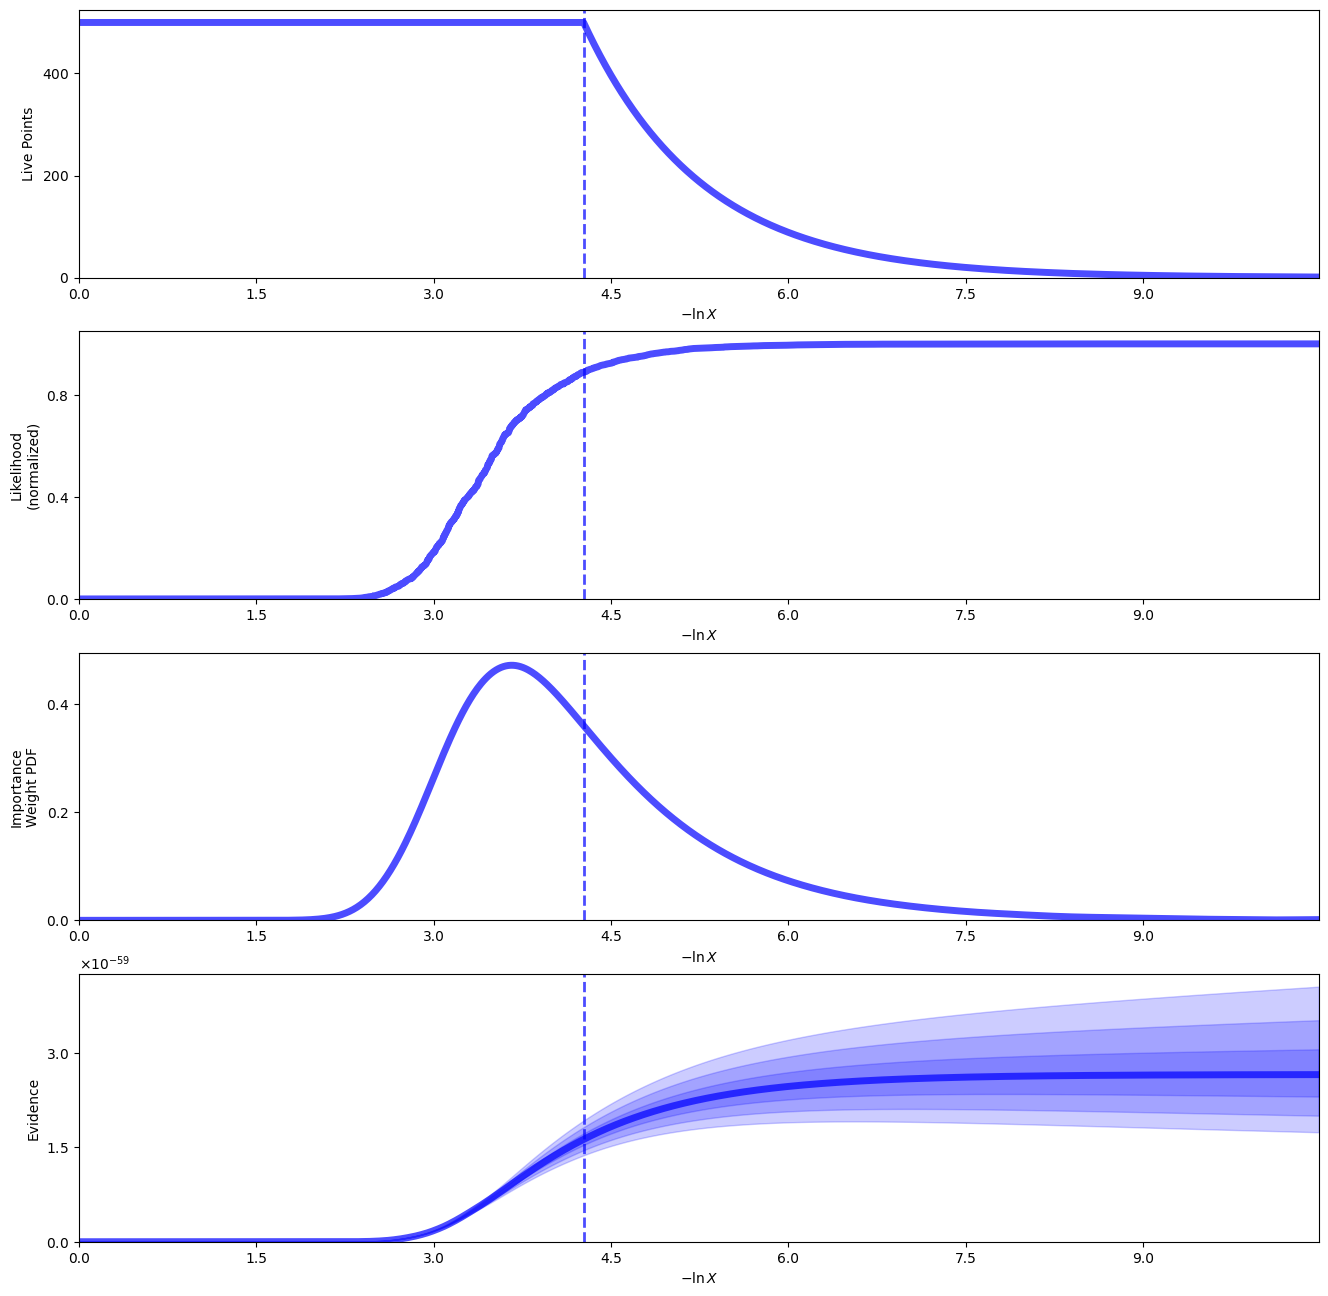

In [ ]:
rfig, raxes = dyplot.runplot(sresults_0)

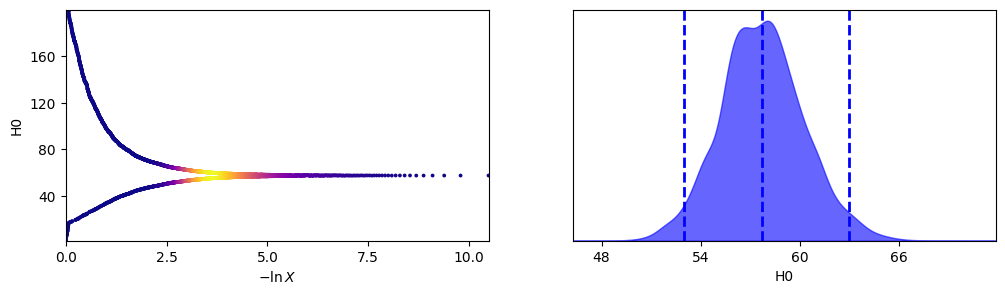

In [ ]:
tfig, taxes = dyplot.traceplot(sresults_0,labels=labels)

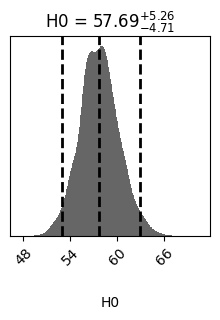

In [ ]:
cfig, caxes = dyplot.cornerplot(sresults_0,labels=labels, show_titles=True)

In [ ]:
evidence = np.exp(sresults.logz[-1]) #evidence burst
print("Bayesian evidence for model BURST =", evidence)
evidence_0= np.exp(sresults_0.logz[-1]) #evidence gaussian  #BOTH LOW BECAUSE I FULLY NORMALIZED THE LOGLIKELIHOOD
print("Bayesian evidence for model GAUSSIAN =", evidence_0)

print(f'the ratio between the BURST AND GAUSSIAN evidences is :{ evidence/evidence_0:.4f}')




Bayesian evidence for model BURST = 5.657067439675838e-59
Bayesian evidence for model GAUSSIAN = 2.652932831755043e-59
the ratio between the BURST AND GAUSSIAN evidences is :2.1324


**Not enough data for strong inference**